## 0. Setup

In [1]:
!pip install -q datasets transformers accelerate seqeval pytorch-crf gradio gensim

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, random, html
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from datasets import load_dataset
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.metrics.sequence_labeling import get_entities

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Load and explore CoNLL-2003
The HuggingFace version already uses the **IOB2** scheme: `B-X` starts every entity, `I-X` continues it, `O` is outside.

In [4]:
STD_LABELS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]

CANDIDATES = [("lhoestq/conll2003", {}),("lukasgarbas/conll-03", {}),("eriktks/conll2003", {"revision": "refs/convert/parquet"}),("eriktks/conll2003", {"trust_remote_code": True}),      ]
ds = None
for repo, kw in CANDIDATES:
    try:
        ds = load_dataset(repo, **kw)
        print("loaded from:", repo, kw)
        break
    except Exception as e:
        print(f"[x] {repo} {kw} -> {type(e).__name__}: {str(e)[:160]}")
assert ds is not None, 'All sources failed. Run: !pip install "datasets<4.0"  then Runtime -> Restart session, and run again.'

feat = ds["train"].features["ner_tags"]
if hasattr(feat, "feature") and hasattr(feat.feature, "names"):
    label_names = feat.feature.names
else:
    label_names = STD_LABELS
    if isinstance(ds["train"][0]["ner_tags"][0], str):
        l2i = {l: i for i, l in enumerate(STD_LABELS)}
        ds = ds.map(lambda b: {"ner_tags": [[l2i[t] for t in seq] for seq in b["ner_tags"]]}, batched=True)

id2label = {i: l for i, l in enumerate(label_names)}
label2id = {l: i for i, l in id2label.items()}
print(ds)
print(label_names)

for i in range(2):
    ex = ds["train"][i]
    print([(t, id2label[y]) for t, y in zip(ex["tokens"], ex["ner_tags"])])

dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

loaded from: lhoestq/conll2003 {}
DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
[('EU', 'B-ORG'), ('rejects', 'O'), ('German', 'B-MISC'), ('call', 'O'), ('to', 'O'), ('boycott', 'O'), ('British', 'B-MISC'), ('lamb', 'O'), ('.', 'O')]
[('Peter', 'B-PER'), ('Blackburn', 'I-PER')]


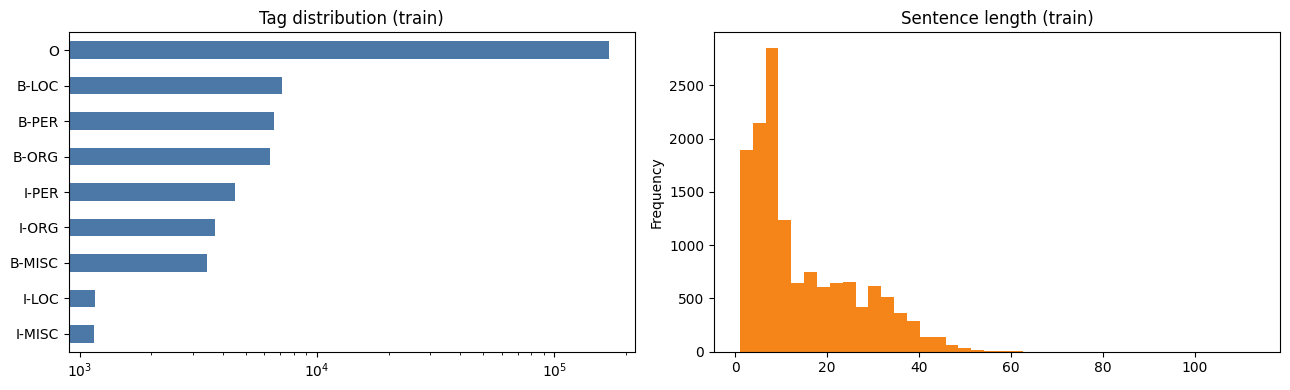

Entity counts in train: {'ORG': 6321, 'MISC': 3438, 'PER': 6600, 'LOC': 7140}


In [5]:
cnt = Counter(id2label[t] for seq in ds["train"]["ner_tags"] for t in seq)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(cnt).sort_values().plot.barh(ax=ax[0], color="#4c78a8", title="Tag distribution (train)")
ax[0].set_xscale("log")
pd.Series([len(t) for t in ds["train"]["tokens"]]).plot.hist(bins=40, ax=ax[1], color="#f58518", title="Sentence length (train)")
plt.tight_layout(); plt.show()

ent_cnt = Counter(e[0] for tags in ds["train"]["ner_tags"] for e in get_entities([id2label[t] for t in tags]))
print("Entity counts in train:", dict(ent_cnt))

## 2. Vocabulary, GloVe embeddings and OOV handling
- **Word level:** pre-trained GloVe 100d (lower-cased lookup).
- **Character level:** a small CNN over characters gives every word, even unseen ones, a vector. It also captures capitalization and suffixes, which matter a lot for NER.
- Vocabulary = train words + any dev/test word that exists in GloVe. Words not in GloVe fall back to `<unk>` + their char-CNN features.

In [6]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")   # ~128 MB, lower-cased
EMB_DIM = glove.vector_size

PAD, UNK = "<pad>", "<unk>"
word2id = {PAD: 0, UNK: 1}
for w in (w.lower() for s in ds["train"]["tokens"] for w in s):
    word2id.setdefault(w, len(word2id))
for split in ["validation", "test"]:
    for s in ds[split]["tokens"]:
        for w in s:
            w = w.lower()
            if w in glove.key_to_index:
                word2id.setdefault(w, len(word2id))

emb_matrix = np.random.normal(0, 0.1, (len(word2id), EMB_DIM)).astype("float32")
emb_matrix[0] = 0
hit = 0
for w, i in word2id.items():
    if w in glove.key_to_index:
        emb_matrix[i] = glove[w]; hit += 1
print(f"vocab={len(word2id)}  found in GloVe={hit} ({hit/len(word2id):.1%})")

char2id = {PAD: 0, UNK: 1}
for s in ds["train"]["tokens"]:
    for w in s:
        for ch in w:
            char2id.setdefault(ch, len(char2id))
print("chars:", len(char2id))

oov = sum(w.lower() not in word2id for s in ds["test"]["tokens"] for w in s)
total = sum(len(s) for s in ds["test"]["tokens"])
print(f"test OOV tokens: {oov}/{total} ({oov/total:.2%})")

[==================================================] 100.0% 128.1/128.1MB downloaded
vocab=25543  found in GloVe=22947 (89.8%)
chars: 86
test OOV tokens: 1143/46435 (2.46%)


## 3. Datasets and DataLoaders

In [7]:
MAX_WORD_LEN = 20

class NERDataset(Dataset):
    def __init__(self, split):
        self.tokens, self.tags = split["tokens"], split["ner_tags"]
    def __len__(self): return len(self.tokens)
    def __getitem__(self, i):
        toks = self.tokens[i]
        w = torch.tensor([word2id.get(t.lower(), 1) for t in toks])
        c = [torch.tensor([char2id.get(ch, 1) for ch in t[:MAX_WORD_LEN]]) for t in toks]
        return w, c, torch.tensor(self.tags[i])

def collate(batch):
    ws, cs, ys = zip(*batch)
    lens = torch.tensor([len(w) for w in ws])
    W = pad_sequence(ws, batch_first=True, padding_value=0)
    Y = pad_sequence(ys, batch_first=True, padding_value=-100)
    B, T = W.shape
    L = max(len(ch) for c in cs for ch in c)
    C = torch.zeros(B, T, L, dtype=torch.long)
    for b, c in enumerate(cs):
        for t, ch in enumerate(c):
            C[b, t, :len(ch)] = ch
    mask = torch.arange(T)[None, :] < lens[:, None]
    return W, C, Y, lens, mask

train_dl = DataLoader(NERDataset(ds["train"]), batch_size=32, shuffle=True, collate_fn=collate)
dev_dl   = DataLoader(NERDataset(ds["validation"]), batch_size=64, collate_fn=collate)
test_dl  = DataLoader(NERDataset(ds["test"]), batch_size=64, collate_fn=collate)

## 4. Models built from scratch
One configurable class, so the three architectures differ **only** in what we want to compare:

| Model | `bidirectional` | `use_crf` |
|---|---|---|
| LSTM | False | False |
| BiLSTM | True | False |
| BiLSTM + CRF | True | True |

Input = GloVe vector concatenated with char-CNN vector.

In [9]:
from torchcrf import CRF

class LSTMTagger(nn.Module):
    def __init__(self, emb_matrix, n_chars, n_tags, bidirectional=True, use_crf=False,
                 char_dim=30, char_filters=50, hidden=256, dropout=0.5):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.char_emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_cnn = nn.Conv1d(char_dim, char_filters, kernel_size=3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.shape[1] + char_filters, hidden, batch_first=True,
                            bidirectional=bidirectional)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), n_tags)
        self.use_crf = use_crf
        if use_crf:
            self.crf = CRF(n_tags, batch_first=True)

    def emissions(self, W, C, lens):
        B, T, L = C.shape
        c = self.char_emb(C.view(B * T, L)).transpose(1, 2)          # (B*T, char_dim, L)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values.view(B, T, -1)
        x = self.drop(torch.cat([self.word_emb(W), c], dim=-1))
        packed = pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=T)
        return self.fc(self.drop(out))

    def loss(self, W, C, lens, mask, Y):
        em = self.emissions(W, C, lens)
        if self.use_crf:
            return -self.crf(em, Y.masked_fill(~mask, 0), mask=mask, reduction="mean")
        return F.cross_entropy(em.view(-1, em.size(-1)), Y.view(-1), ignore_index=-100)

    @torch.no_grad()
    def predict(self, W, C, lens, mask):
        em = self.emissions(W, C, lens)
        if self.use_crf:
            return self.crf.decode(em, mask=mask)
        return [em[b, :lens[b]].argmax(-1).tolist() for b in range(em.size(0))]

## 5. Training and evaluation helpers

In [10]:
def predict_split(model, loader):
    model.eval()
    preds, golds = [], []
    for W, C, Y, lens, mask in loader:
        out = model.predict(W.to(device), C.to(device), lens, mask.to(device))
        for b, pb in enumerate(out):
            n = lens[b].item()
            preds.append([id2label[i] for i in pb[:n]])
            golds.append([id2label[i] for i in Y[b, :n].tolist()])
    return preds, golds

def train_model(name, bidirectional, use_crf, epochs=20, patience=4, lr=1e-3):
    set_seed()
    model = LSTMTagger(emb_matrix, len(char2id), len(label_names), bidirectional, use_crf).to(device)
    crf_params = [p for n, p in model.named_parameters() if n.startswith("crf")]
    other = [p for n, p in model.named_parameters() if not n.startswith("crf")]
    groups = [{"params": other, "lr": lr}]
    if crf_params:
        groups.append({"params": crf_params, "lr": lr * 10})   # transitions learn faster
    opt = torch.optim.Adam(groups)
    path, best, bad, hist = f"{name.replace('+','_')}.pt", 0.0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); total = 0.0
        for W, C, Y, lens, mask in train_dl:
            W, C, Y, mask = W.to(device), C.to(device), Y.to(device), mask.to(device)
            opt.zero_grad()
            loss = model.loss(W, C, lens, mask, Y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); total += loss.item()
        p, g = predict_split(model, dev_dl)
        f1 = f1_score(g, p)
        hist.append({"epoch": ep, "loss": total / len(train_dl), "dev_f1": f1})
        print(f"[{name}] epoch {ep:02d}  loss={total/len(train_dl):.4f}  dev F1={f1:.4f}")
        if f1 > best:
            best, bad = f1, 0; torch.save(model.state_dict(), path)
        else:
            bad += 1
            if bad >= patience:
                print("early stop"); break
    model.load_state_dict(torch.load(path, map_location=device))
    return model, pd.DataFrame(hist)

all_preds, histories = {}, {}
CONFIGS = {"LSTM": (False, False), "BiLSTM": (True, False), "BiLSTM+CRF": (True, True)}

## 6. Train LSTM, BiLSTM, BiLSTM+CRF

In [11]:
models = {}
for name, (bi, crf) in CONFIGS.items():
    models[name], histories[name] = train_model(name, bi, crf)
    p, g = predict_split(models[name], test_dl)
    all_preds[name] = (p, g)
    print(f"\n=== {name} | TEST ===")
    print(classification_report(g, p, digits=4))

[LSTM] epoch 01  loss=0.3758  dev F1=0.7907
[LSTM] epoch 02  loss=0.1468  dev F1=0.8248
[LSTM] epoch 03  loss=0.1111  dev F1=0.8451
[LSTM] epoch 04  loss=0.0918  dev F1=0.8522
[LSTM] epoch 05  loss=0.0797  dev F1=0.8615
[LSTM] epoch 06  loss=0.0702  dev F1=0.8631
[LSTM] epoch 07  loss=0.0638  dev F1=0.8663
[LSTM] epoch 08  loss=0.0573  dev F1=0.8695
[LSTM] epoch 09  loss=0.0514  dev F1=0.8694
[LSTM] epoch 10  loss=0.0477  dev F1=0.8726
[LSTM] epoch 11  loss=0.0436  dev F1=0.8697
[LSTM] epoch 12  loss=0.0401  dev F1=0.8677
[LSTM] epoch 13  loss=0.0365  dev F1=0.8755
[LSTM] epoch 14  loss=0.0353  dev F1=0.8753
[LSTM] epoch 15  loss=0.0319  dev F1=0.8753
[LSTM] epoch 16  loss=0.0303  dev F1=0.8743
[LSTM] epoch 17  loss=0.0288  dev F1=0.8769
[LSTM] epoch 18  loss=0.0275  dev F1=0.8788
[LSTM] epoch 19  loss=0.0255  dev F1=0.8776
[LSTM] epoch 20  loss=0.0238  dev F1=0.8783

=== LSTM | TEST ===
              precision    recall  f1-score   support

         LOC     0.8046    0.9137    0.8557 

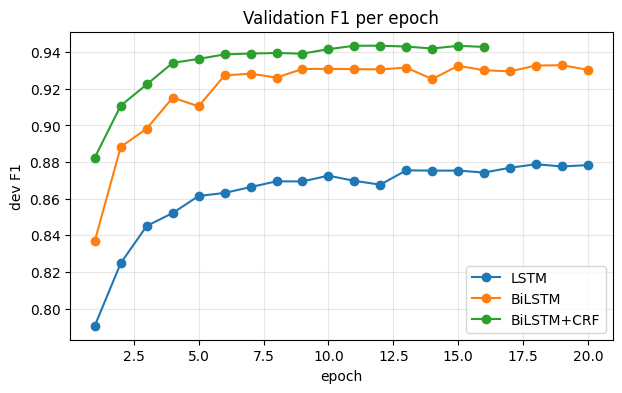

In [12]:
plt.figure(figsize=(7, 4))
for n, h in histories.items():
    plt.plot(h["epoch"], h["dev_f1"], marker="o", label=n)
plt.xlabel("epoch"); plt.ylabel("dev F1"); plt.title("Validation F1 per epoch"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 7. Fine-tune a transformer (HuggingFace)
Subword tokenization splits words into pieces, so labels must be **aligned**: we label the first sub-token of each word with the word's tag and mask the rest with `-100` (ignored by the loss and by evaluation).

In [13]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, TrainingArguments, Trainer)

MODEL_CKPT = "distilbert-base-cased"      # or "bert-base-cased" for a stronger (slower) model
tok = AutoTokenizer.from_pretrained(MODEL_CKPT)

def tokenize_and_align(batch):
    enc = tok(batch["tokens"], truncation=True, is_split_into_words=True)
    all_labels = []
    for i, tags in enumerate(batch["ner_tags"]):
        prev, labs = None, []
        for wid in enc.word_ids(batch_index=i):
            if wid is None:        labs.append(-100)          # special tokens
            elif wid != prev:      labs.append(tags[wid])     # first sub-token gets the tag
            else:                  labs.append(-100)          # remaining sub-tokens ignored
            prev = wid
        all_labels.append(labs)
    enc["labels"] = all_labels
    return enc

tokenized = ds.map(tokenize_and_align, batched=True, remove_columns=ds["train"].column_names)

# alignment demo
ex = ds["train"][0]
enc = tok(ex["tokens"], is_split_into_words=True)
print(list(zip(tok.convert_ids_to_tokens(enc["input_ids"]), tokenized["train"][0]["labels"])))

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

[('[CLS]', -100), ('EU', 3), ('rejects', 0), ('German', 7), ('call', 0), ('to', 0), ('boycott', 0), ('British', 7), ('la', 0), ('##mb', -100), ('.', 0), ('[SEP]', -100)]


In [14]:
def to_label_lists(logits, labels):
    preds = np.argmax(logits, axis=-1)
    p_out = [[id2label[p] for p, l in zip(pr, lb) if l != -100] for pr, lb in zip(preds, labels)]
    g_out = [[id2label[l] for l in lb if l != -100] for lb in labels]
    return p_out, g_out

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    p, g = to_label_lists(logits, labels)
    return {"precision": precision_score(g, p), "recall": recall_score(g, p), "f1": f1_score(g, p)}

hf_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CKPT, num_labels=len(label_names), id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="ner-distilbert-ckpt",
    eval_strategy="epoch", save_strategy="epoch",
    learning_rate=2e-5, weight_decay=0.01,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=3,
    load_best_model_at_end=True, metric_for_best_model="f1",
    fp16=torch.cuda.is_available(), report_to="none", seed=SEED,
)
trainer_kwargs = dict(model=hf_model, args=args,
                      train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                      data_collator=DataCollatorForTokenClassification(tok),
                      compute_metrics=compute_metrics)
try:
    trainer = Trainer(processing_class=tok, **trainer_kwargs)     # recent transformers
except TypeError:
    trainer = Trainer(tokenizer=tok, **trainer_kwargs)            # older versions
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,No log,0.062971,0.888796,0.894480,0.891629
2,0.164874,0.051630,0.920000,0.921239,0.920619
3,0.042738,0.047619,0.922602,0.930831,0.926699


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1317, training_loss=0.08569192922558853, metrics={'train_runtime': 110.2195, 'train_samples_per_second': 382.174, 'train_steps_per_second': 11.949, 'total_flos': 582119704739538.0, 'train_loss': 0.08569192922558853, 'epoch': 3.0})

In [15]:
out = trainer.predict(tokenized["test"])
p, g = to_label_lists(out.predictions, out.label_ids)
all_preds["DistilBERT"] = (p, g)
print("=== DistilBERT | TEST ===")
print(classification_report(g, p, digits=4))

trainer.save_model("ner-distilbert"); tok.save_pretrained("ner-distilbert")

=== DistilBERT | TEST ===
              precision    recall  f1-score   support

         LOC     0.9113    0.9113    0.9113      1668
        MISC     0.7242    0.7892    0.7553       702
         ORG     0.8397    0.8802    0.8595      1661
         PER     0.9587    0.9468    0.9527      1617

   micro avg     0.8780    0.8971    0.8875      5648
   macro avg     0.8585    0.8819    0.8697      5648
weighted avg     0.8806    0.8971    0.8885      5648



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('ner-distilbert/tokenizer_config.json', 'ner-distilbert/tokenizer.json')

## 8. Comparison of all architectures (seqeval)

,PER F1,ORG F1,LOC F1,MISC F1,Precision,Recall,Overall F1
Model,,,,,,,
LSTM,0.9309,0.7416,0.8557,0.6788,0.7996,0.8435,0.8210
BiLSTM,0.9508,0.8500,0.9072,0.8006,0.8810,0.8982,0.8895
BiLSTM+CRF,0.9537,0.8769,0.9252,0.8022,0.9050,0.9021,0.9035
DistilBERT,0.9527,0.8595,0.9113,0.7553,0.8780,0.8971,0.8875


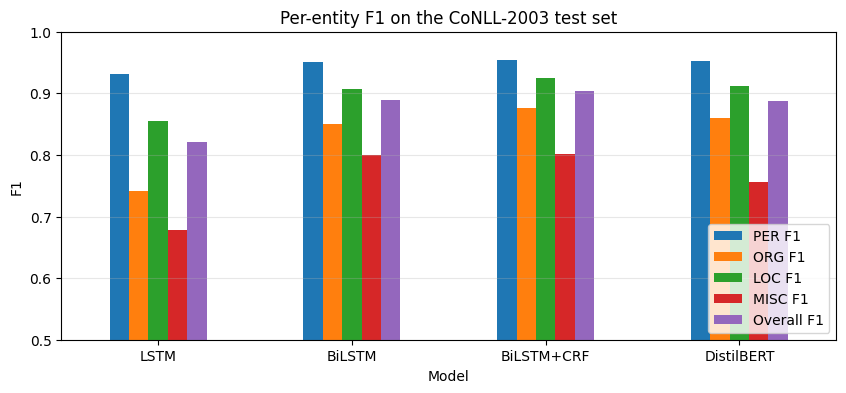

In [16]:
rows = []
for name, (p, g) in all_preds.items():
    rep = classification_report(g, p, output_dict=True)
    row = {"Model": name}
    for ent in ["PER", "ORG", "LOC", "MISC"]:
        row[f"{ent} F1"] = round(rep[ent]["f1-score"], 4)
    row["Precision"] = round(precision_score(g, p), 4)
    row["Recall"]    = round(recall_score(g, p), 4)
    row["Overall F1"] = round(f1_score(g, p), 4)
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Model")
display(summary)

summary[["PER F1", "ORG F1", "LOC F1", "MISC F1", "Overall F1"]].plot.bar(figsize=(10, 4), rot=0)
plt.ylim(0.5, 1.0); plt.ylabel("F1"); plt.title("Per-entity F1 on the CoNLL-2003 test set"); plt.grid(axis="y", alpha=.3)
plt.legend(loc="lower right"); plt.show()

## 9. Where does the CRF improve boundary detection?
A softmax tagger predicts every tag **independently**, so it can output illegal or inconsistent IOB sequences such as `O -> I-PER` or `B-ORG -> I-LOC`, and it often cuts an entity too short or too long. A CRF scores the **whole tag sequence** (emission + transition scores) and decodes it jointly with Viterbi, so it learns that `I-X` must follow `B-X`/`I-X`.

We measure this with two numbers per model:
- **Invalid IOB transitions:** `I-X` that does not follow `B-X`/`I-X` of the same type.
- **Boundary errors:** predicted spans with the correct type that overlap a gold span but do not match it exactly.

In [17]:
def invalid_transitions(seqs):
    n = 0
    for s in seqs:
        prev = "O"
        for t in s:
            if t.startswith("I-") and (prev == "O" or prev[2:] != t[2:]):
                n += 1
            prev = t
    return n

def boundary_stats(golds, preds):
    boundary = spurious = missed = 0
    for g, p in zip(golds, preds):
        G, P = set(get_entities(g)), set(get_entities(p))
        for t, s, e in P - G:
            if any(gt == t and s <= ge and gs <= e for gt, gs, ge in G):
                boundary += 1
            else:
                spurious += 1
        missed += len(G - P)
    return boundary, spurious, missed

rows = []
for name, (p, g) in all_preds.items():
    b, sp, ms = boundary_stats(g, p)
    rows.append({"Model": name, "Invalid IOB transitions": invalid_transitions(p),
                 "Boundary errors (right type, wrong span)": b,
                 "Spurious entities": sp, "Gold entities not matched": ms})
display(pd.DataFrame(rows).set_index("Model"))

,Invalid IOB transitions,"Boundary errors (right type, wrong span)",Spurious entities,Gold entities not matched
Model,,,,
LSTM,325,310,884,884
BiLSTM,85,127,558,575
BiLSTM+CRF,0,82,453,553
DistilBERT,98,132,572,581


In [18]:
# Concrete examples where BiLSTM and BiLSTM+CRF disagree on spans
p_bi, gold = all_preds["BiLSTM"]
p_crf, _ = all_preds["BiLSTM+CRF"]
test_tokens = ds["test"]["tokens"]
shown = 0
for i, (a, b, g) in enumerate(zip(p_bi, p_crf, gold)):
    if set(get_entities(a)) != set(get_entities(b)) and set(get_entities(b)) == set(get_entities(g)):
        print(" ".join(test_tokens[i]))
        print("  gold      :", get_entities(g))
        print("  BiLSTM    :", get_entities(a))
        print("  BiLSTM+CRF:", get_entities(b), "\n")
        shown += 1
        if shown == 5: break

Astle 9-0-53-1 ( w-1 nb-1 )
  gold      : [('PER', 0, 0)]
  BiLSTM    : []
  BiLSTM+CRF: [('PER', 0, 0)] 

BASKETBALL - EUROLEAGUE STANDINGS .
  gold      : [('MISC', 2, 2)]
  BiLSTM    : [('ORG', 2, 2)]
  BiLSTM+CRF: [('MISC', 2, 2)] 

Maccabi Tel Aviv ( Israel ) 9 5 4 14
  gold      : [('ORG', 0, 2), ('LOC', 4, 4)]
  BiLSTM    : [('ORG', 1, 2), ('LOC', 4, 4)]
  BiLSTM+CRF: [('ORG', 0, 2), ('LOC', 4, 4)] 

Limoges ( France ) 9 3 6 12
  gold      : [('ORG', 0, 0), ('LOC', 2, 2)]
  BiLSTM    : [('LOC', 0, 0), ('LOC', 2, 2)]
  BiLSTM+CRF: [('ORG', 0, 0), ('LOC', 2, 2)] 

Charleroi ( Belgium ) 9 0 9 9
  gold      : [('ORG', 0, 0), ('LOC', 2, 2)]
  BiLSTM    : [('LOC', 0, 0), ('LOC', 2, 2)]
  BiLSTM+CRF: [('ORG', 0, 0), ('LOC', 2, 2)] 



**Results and analysis (CoNLL-2003 test set):**

| Model | Overall F1 | Invalid IOB transitions | Boundary errors |
|---|---|---|---|
| LSTM | 0.8210 | 325 | 310 |
| BiLSTM | 0.8895 | 85 | 127 |
| BiLSTM + CRF | 0.9035 | 0 | 82 |
| DistilBERT | 0.8875 | 98 | 132 |

- **LSTM -> BiLSTM (+6.9 F1 points):** reading the sentence in both directions gives right-context, the biggest single gain, mostly on ORG (0.74 -> 0.85) and MISC (0.68 -> 0.80).
- **BiLSTM -> BiLSTM+CRF (+1.4 points):** the CRF scores the whole tag sequence, so invalid IOB transitions drop from 85 to 0 and boundary errors from 127 to 82 (about 35% fewer). Example: for "Maccabi Tel Aviv" the BiLSTM tagged only "Tel Aviv" as ORG, while the CRF recovered the full span.
- **DistilBERT (0.8875) did not beat BiLSTM+CRF in this run.** It was fine-tuned for only 3 epochs as a small distilled model, on single sentences. Its softmax head still produces 98 invalid transitions, like the BiLSTM. More epochs or `bert-base-cased` would likely help (not tested here).


## 10. Color-coded entity visualization

In [19]:
from transformers import pipeline
from IPython.display import HTML, display

ner = pipeline("token-classification", model="ner-distilbert", aggregation_strategy="simple",
               device=0 if torch.cuda.is_available() else -1)

COLORS = {"PER": "#ff9aa2", "ORG": "#8ecae6", "LOC": "#b5e48c", "MISC": "#ffd6a5"}

def highlight_html(text, ents):
    out, last = [], 0
    for e in sorted(ents, key=lambda e: e["start"]):
        g = e["entity_group"]
        out.append(html.escape(text[last:e["start"]]))
        out.append(f'<mark style="background:{COLORS.get(g, "#ddd")};padding:2px 6px;border-radius:6px;margin:0 2px">'
                   f'{html.escape(text[e["start"]:e["end"]])} <b style="font-size:.7em">{g}</b></mark>')
        last = e["end"]
    out.append(html.escape(text[last:]))
    return "".join(out)

text = "Barack Obama visited Microsoft headquarters in Seattle on Monday, then flew to Cairo with the Egyptian delegation."
display(HTML(highlight_html(text, ner(text))))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

## 11. Deployment with Gradio
Type free text and the entities are highlighted live (updates as you type).

In [20]:
import gradio as gr

def predict(text):
    if not text or not text.strip():
        return {"text": "", "entities": []}
    ents = ner(text)
    return {"text": text,
            "entities": [{"entity": e["entity_group"], "start": e["start"], "end": e["end"]} for e in ents]}

examples = [
    "Apple CEO Tim Cook announced a new campus in Austin, Texas.",
    "Mohamed Salah scored twice for Liverpool against Manchester United at Anfield.",
    "The United Nations met in Geneva to discuss the European Union sanctions.",
]

with gr.Blocks(title="NER System") as demo:
    gr.Markdown("# Named Entity Recognition\nDistilBERT fine-tuned on CoNLL-2003 - **PER / ORG / LOC / MISC**")
    inp = gr.Textbox(lines=4, label="Enter text", placeholder="Type or paste any English text...")
    out = gr.HighlightedText(label="Detected entities", color_map=COLORS, show_legend=True)
    gr.Examples(examples, inputs=inp)
    inp.change(predict, inp, out)          # real-time highlighting

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://85a4b4683095d96aef.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### (Optional) Deploy on HuggingFace Spaces
1. Push the model: `trainer.push_to_hub("your-username/ner-distilbert")` (after `huggingface-cli login`).
2. Create a Gradio Space, put the code of the previous cell in `app.py` with `model="your-username/ner-distilbert"`, and add `transformers`, `torch` to `requirements.txt`.